In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# قراءة ملف البيانات
df = pd.read_csv("flights.csv")

# عرض أول 5 صفوف
print("أول خمسة صفوف:")
display(df.head())

# عرض أسماء الأعمدة
print("\nأسماء الأعمدة:")
print(df.columns.tolist())

# حجم البيانات
print("\nحجم البيانات (صفوف، أعمدة):")
print(df.shape)

# معلومات عن أنواع البيانات والقيم المفقودة
print("\nمعلومات البيانات:")
df.info()

print("\nعدد القيم المفقودة:")
print(df.isnull().sum())

أول خمسة صفوف:


,observation_date,ENPLANED
0,2000-01-01,41540
1,2000-02-01,43714
2,2000-03-01,52977
3,2000-04-01,50344
4,2000-05-01,52309



أسماء الأعمدة:
['observation_date', 'ENPLANED']

حجم البيانات (صفوف، أعمدة):
(318, 2)

معلومات البيانات:
<class 'pandas.DataFrame'>
RangeIndex: 318 entries, 0 to 317
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   observation_date  318 non-null    str  
 1   ENPLANED          318 non-null    int64
dtypes: int64(1), str(1)
memory usage: 8.2 KB

عدد القيم المفقودة:
observation_date    0
ENPLANED            0
dtype: int64


In [3]:
# تحويل عمود التاريخ إلى نوع تاريخ فعلي
df["observation_date"] = pd.to_datetime(df["observation_date"])

# ترتيب البيانات زمنيًا
df = df.sort_values("observation_date").reset_index(drop=True)

# فحص الفترة الزمنية
print("أول شهر:", df["observation_date"].min().strftime("%Y-%m"))
print("آخر شهر:", df["observation_date"].max().strftime("%Y-%m"))
print("عدد الصفوف:", len(df))

# فحص التواريخ المكررة
print("عدد التواريخ المكررة:", df["observation_date"].duplicated().sum())

# فحص الأشهر المفقودة
all_months = pd.date_range(
    start=df["observation_date"].min(),
    end=df["observation_date"].max(),
    freq="MS"
)

missing_months = all_months.difference(
    pd.DatetimeIndex(df["observation_date"])
)

print("عدد الأشهر المفقودة:", len(missing_months))
if len(missing_months) > 0:
    print("الأشهر المفقودة:", missing_months.strftime("%Y-%m").tolist())

# فحص القيم غير المنطقية
print("عدد القيم الصفرية أو السالبة:", (df["ENPLANED"] <= 0).sum())

# عرض آخر خمسة صفوف
display(df.tail())

أول شهر: 2000-01
آخر شهر: 2026-06
عدد الصفوف: 318
عدد التواريخ المكررة: 0
عدد الأشهر المفقودة: 0
عدد القيم الصفرية أو السالبة: 0


,observation_date,ENPLANED
313,2026-02-01,59391
314,2026-03-01,73163
315,2026-04-01,69820
316,2026-05-01,73760
317,2026-06-01,75467


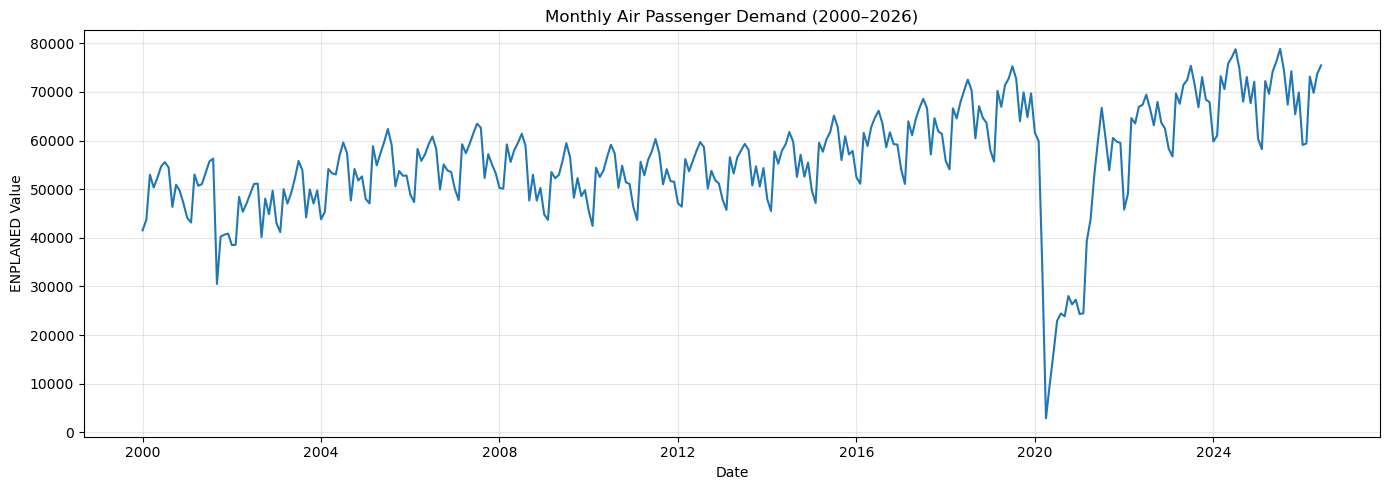

In [4]:
# رسم الطلب الشهري على الرحلات الجوية عبر الزمن

plt.figure(figsize=(14, 5))

plt.plot(
    df["observation_date"],
    df["ENPLANED"],
    linewidth=1.5
)

plt.title("Monthly Air Passenger Demand (2000–2026)")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

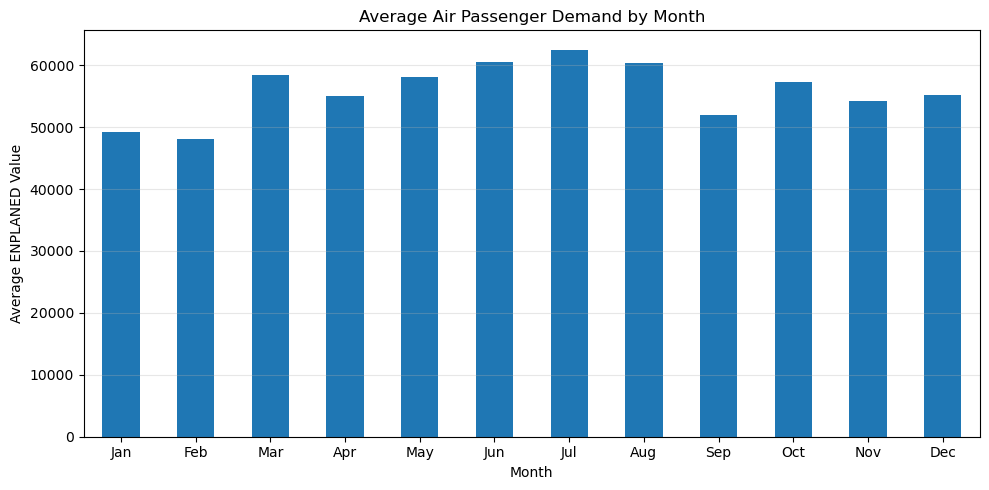

In [5]:
df["month"] = df["observation_date"].dt.month

monthly_seasonality = (
    df.groupby("month")["ENPLANED"]
    .mean()
)

plt.figure(figsize=(10, 5))
monthly_seasonality.plot(kind="bar")

plt.title("Average Air Passenger Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average ENPLANED Value")
plt.xticks(
    ticks=range(12),
    labels=[
        "Jan", "Feb", "Mar", "Apr", "May", "Jun",
        "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
    ],
    rotation=0
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

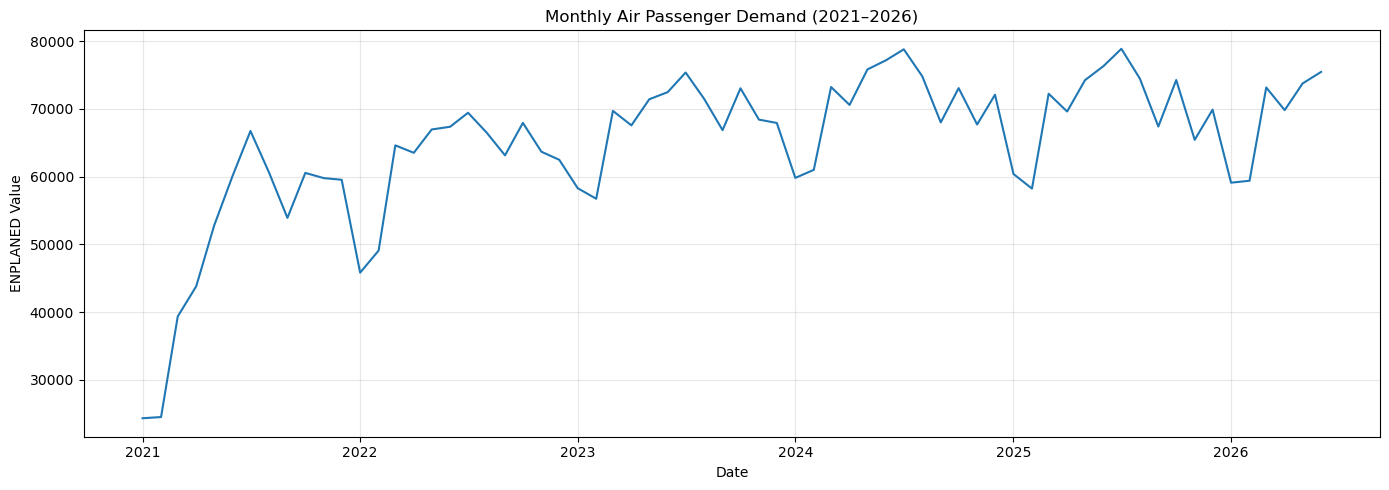

عدد الأشهر: 318
آخر شهر متوفر: 2026-06
عدد القيم المفقودة: 0


In [6]:
# تجهيز السلسلة الزمنية الشهرية
ts = df.set_index("observation_date")["ENPLANED"].asfreq("MS")

# عرض آخر 5 سنوات تقريبًا
recent_ts = ts.loc["2021-01-01":]

plt.figure(figsize=(14, 5))
plt.plot(recent_ts.index, recent_ts.values, linewidth=1.5)

plt.title("Monthly Air Passenger Demand (2021–2026)")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("عدد الأشهر:", len(ts))
print("آخر شهر متوفر:", ts.index.max().strftime("%Y-%m"))
print("عدد القيم المفقودة:", ts.isna().sum())

بداية بيانات التدريب: 2000-01
نهاية بيانات التدريب: 2024-06
عدد أشهر التدريب: 294

بداية بيانات الاختبار: 2024-07
نهاية بيانات الاختبار: 2026-06
عدد أشهر الاختبار: 24


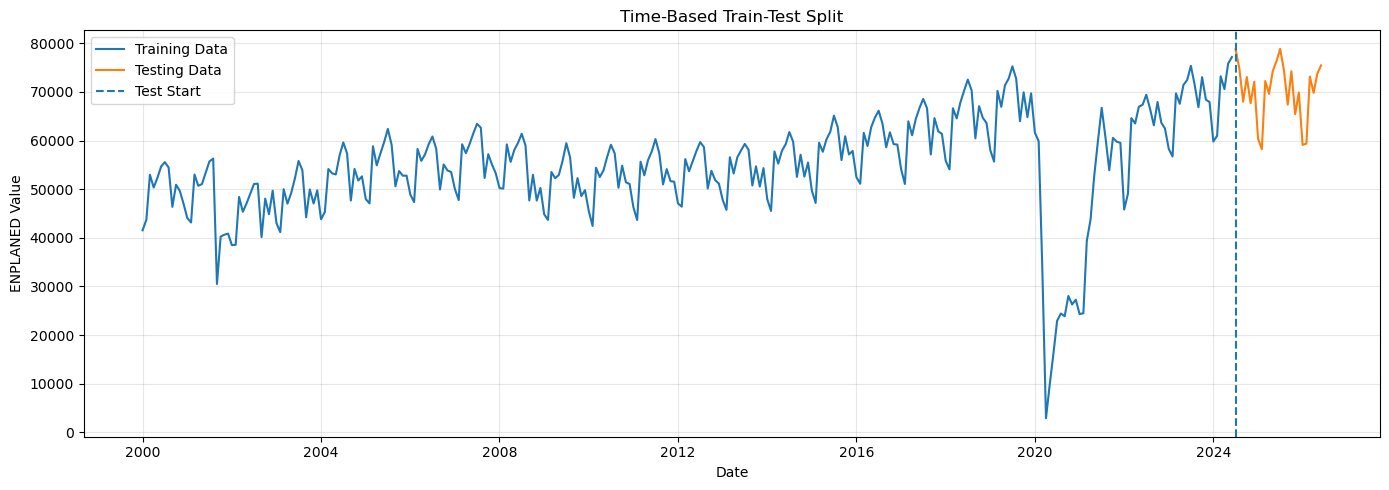

In [7]:
# تقسيم زمني: آخر 24 شهرًا للاختبار
test_size = 24

train = ts.iloc[:-test_size]
test = ts.iloc[-test_size:]

print("بداية بيانات التدريب:", train.index.min().strftime("%Y-%m"))
print("نهاية بيانات التدريب:", train.index.max().strftime("%Y-%m"))
print("عدد أشهر التدريب:", len(train))

print("\nبداية بيانات الاختبار:", test.index.min().strftime("%Y-%m"))
print("نهاية بيانات الاختبار:", test.index.max().strftime("%Y-%m"))
print("عدد أشهر الاختبار:", len(test))

# رسم التقسيم
plt.figure(figsize=(14, 5))
plt.plot(train.index, train.values, label="Training Data")
plt.plot(test.index, test.values, label="Testing Data")

plt.axvline(test.index[0], linestyle="--", label="Test Start")
plt.title("Time-Based Train-Test Split")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

نتائج Seasonal Naive:
MAE: 1696.04
RMSE: 2060.15
MAPE: 2.40%


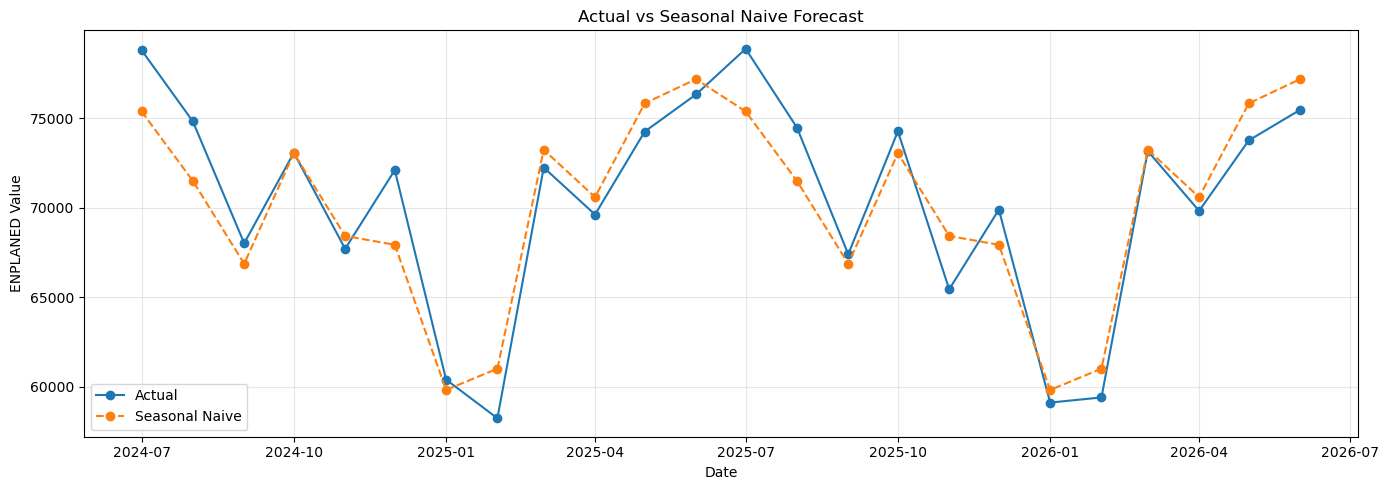

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# التنبؤ بقيمة الشهر نفسه من السنة السابقة
baseline_pred = train.iloc[-12:].to_numpy()
baseline_pred = np.tile(baseline_pred, 2)

# حساب مقاييس الأداء
mae = mean_absolute_error(test, baseline_pred)
rmse = np.sqrt(mean_squared_error(test, baseline_pred))
mape = np.mean(np.abs((test.to_numpy() - baseline_pred) / test.to_numpy())) * 100

print("نتائج Seasonal Naive:")
print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")

# مقارنة القيم الحقيقية بالتنبؤات
plt.figure(figsize=(14, 5))
plt.plot(test.index, test.values, marker="o", label="Actual")
plt.plot(test.index, baseline_pred, marker="o", linestyle="--", label="Seasonal Naive")

plt.title("Actual vs Seasonal Naive Forecast")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

نتائج Holt-Winters:
MAE: 4080.91
RMSE: 4768.65
MAPE: 6.07%


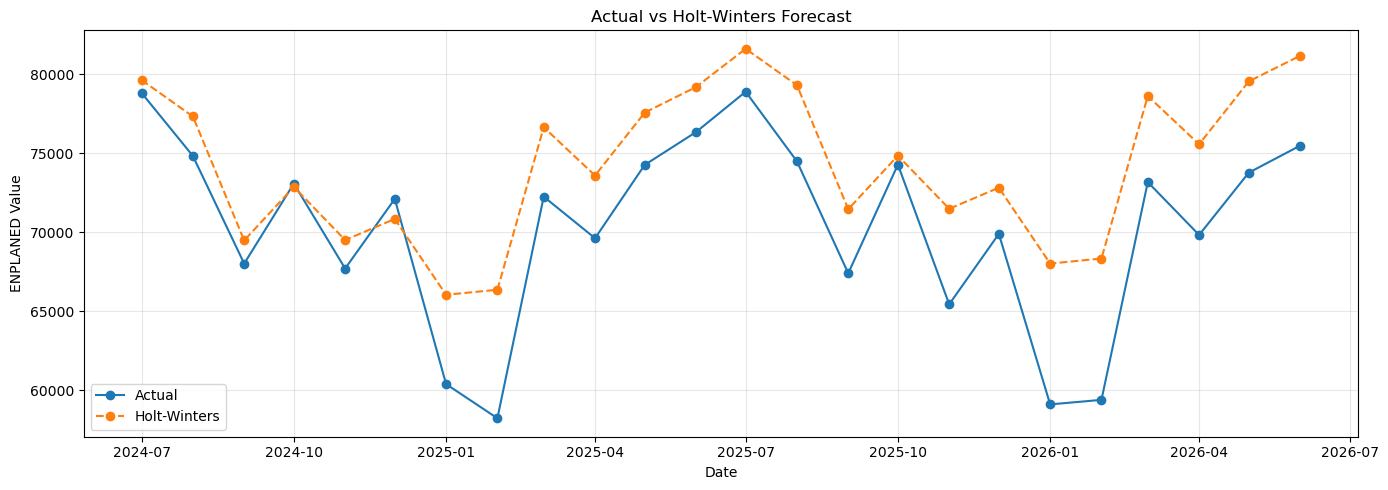

In [9]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# تدريب نموذج Holt-Winters
hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(optimized=True)

# التنبؤ خلال فترة الاختبار (24 شهرًا)
hw_pred = hw_fit.forecast(len(test))

# حساب مقاييس الأداء
hw_mae = mean_absolute_error(test, hw_pred)
hw_rmse = np.sqrt(mean_squared_error(test, hw_pred))
hw_mape = np.mean(
    np.abs((test.to_numpy() - hw_pred.to_numpy()) / test.to_numpy())
) * 100

print("نتائج Holt-Winters:")
print(f"MAE: {hw_mae:.2f}")
print(f"RMSE: {hw_rmse:.2f}")
print(f"MAPE: {hw_mape:.2f}%")

# رسم القيم الفعلية والتنبؤات
plt.figure(figsize=(14, 5))

plt.plot(
    test.index,
    test.values,
    marker="o",
    label="Actual"
)

plt.plot(
    hw_pred.index,
    hw_pred.values,
    linestyle="--",
    marker="o",
    label="Holt-Winters"
)

plt.title("Actual vs Holt-Winters Forecast")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.


نتائج Holt-Winters:
MAE: 4080.91
RMSE: 4768.65
MAPE: 6.07%


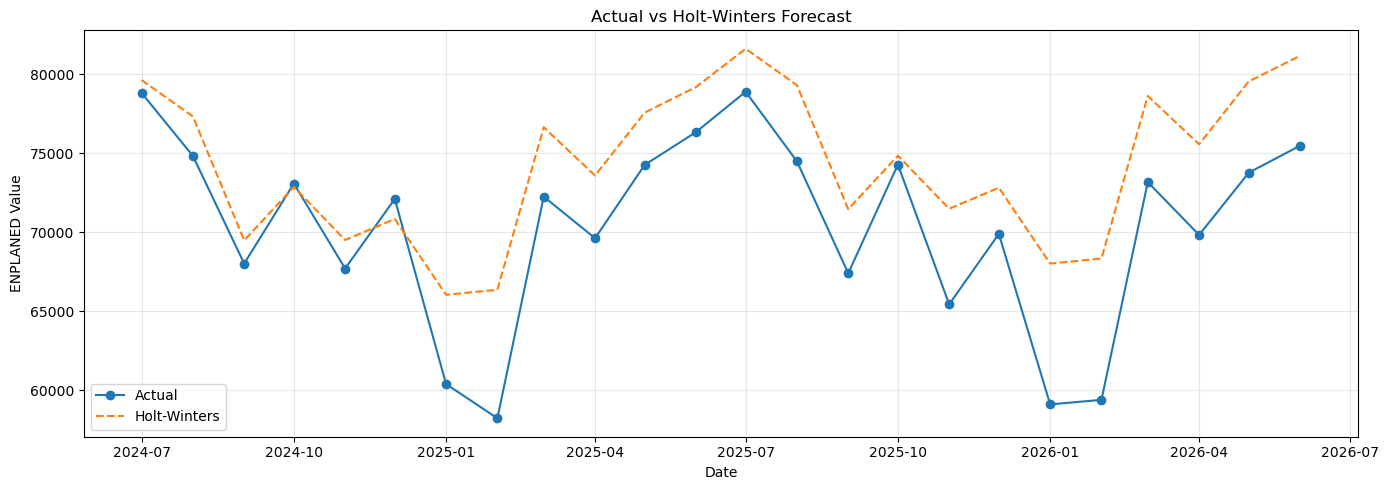

In [11]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# تدريب النموذج
hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=12,
    initialization_method="estimated"
)

hw_fit = hw_model.fit(optimized=True)

# التنبؤ لفترة الاختبار
hw_pred = hw_fit.forecast(len(test))

# حساب مقاييس الأداء
hw_mae = mean_absolute_error(test, hw_pred)
hw_rmse = np.sqrt(mean_squared_error(test, hw_pred))
hw_mape = np.mean(
    np.abs((test.to_numpy() - hw_pred.to_numpy()) / test.to_numpy())
) * 100

print("نتائج Holt-Winters:")
print(f"MAE: {hw_mae:.2f}")
print(f"RMSE: {hw_rmse:.2f}")
print(f"MAPE: {hw_mape:.2f}%")

# رسم المقارنة
plt.figure(figsize=(14, 5))
plt.plot(test.index, test.values, marker="o", label="Actual")
plt.plot(hw_pred.index, hw_pred.values, linestyle="--", label="Holt-Winters")

plt.title("Actual vs Holt-Winters Forecast")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# تجهيز الخصائص الزمنية للتنبؤ العددي
import pandas as pd
import numpy as np

data = pd.DataFrame({"ENPLANED": ts})

# خصائص التاريخ
data["year"] = data.index.year
data["month"] = data.index.month
data["quarter"] = data.index.quarter
data["time_index"] = np.arange(len(data))

# خصائص الأشهر السابقة
for lag in [1, 2, 3, 6, 12]:
    data[f"lag_{lag}"] = data["ENPLANED"].shift(lag)

# متوسط الطلب خلال آخر 3 و12 شهرًا، باستخدام الماضي فقط
data["rolling_mean_3"] = data["ENPLANED"].shift(1).rolling(3).mean()
data["rolling_mean_12"] = data["ENPLANED"].shift(1).rolling(12).mean()

# حذف الصفوف التي لا تتوفر لها قيم سابقة كاملة
data = data.dropna()

# فصل الهدف عن الخصائص
X = data.drop(columns=["ENPLANED"])
y = data["ENPLANED"]

# الحفاظ على التقسيم الزمني نفسه: آخر 24 شهرًا للاختبار
test_start = test.index[0]

X_train = X.loc[X.index < test_start]
X_test = X.loc[X.index >= test_start]

y_train = y.loc[y.index < test_start]
y_test = y.loc[y.index >= test_start]

print("عدد خصائص الإدخال:", X.shape[1])
print("حجم التدريب:", X_train.shape)
print("حجم الاختبار:", X_test.shape)
print("بداية الاختبار:", X_test.index.min().strftime("%Y-%m"))
print("نهاية الاختبار:", X_test.index.max().strftime("%Y-%m"))

عدد خصائص الإدخال: 11
حجم التدريب: (282, 11)
حجم الاختبار: (24, 11)
بداية الاختبار: 2024-07
نهاية الاختبار: 2026-06


مقارنة أداء النموذجين:


/opt/anaconda3/envs/code1/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (3000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Model,MAE,RMSE,MAPE (%)
0,XGBoost,3247.50,4199.64,4.82
1,ANN,17766.33,19787.45,25.22


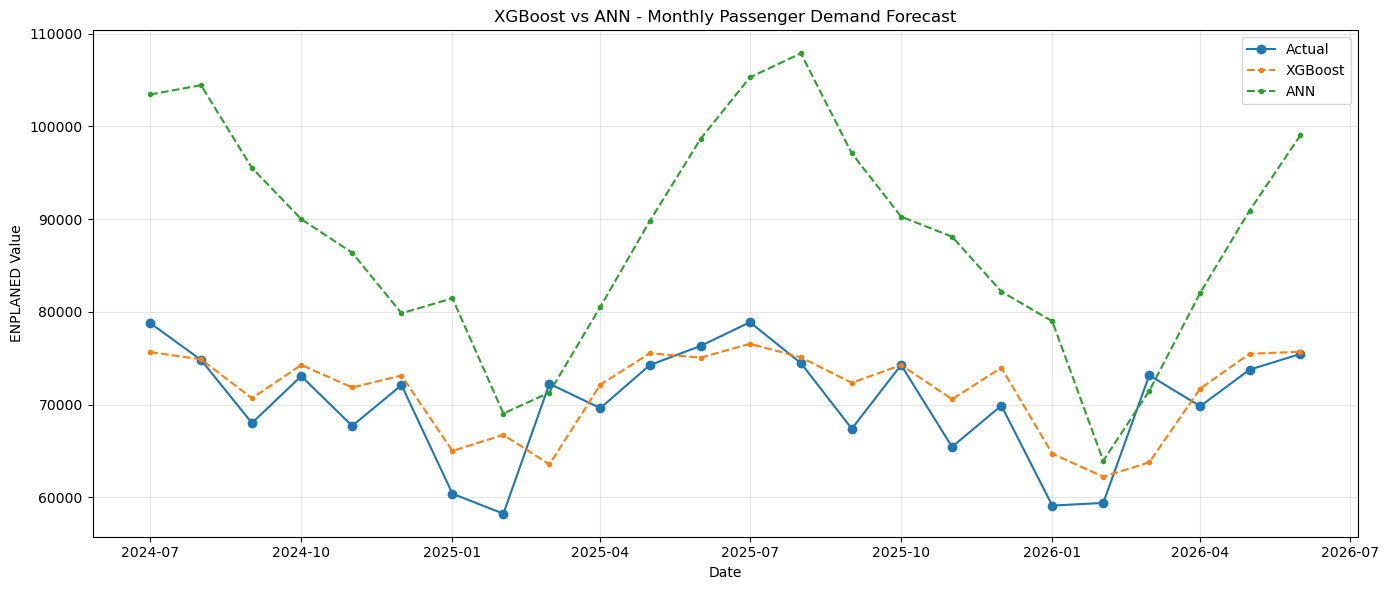

In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. تدريب نموذج XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42
)

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

# 2. تدريب نموذج ANN
ann_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        max_iter=3000,
        early_stopping=False,
        random_state=42
    )
)

ann_model.fit(X_train, y_train)
ann_pred = ann_model.predict(X_test)

# 3. حساب مقاييس الأداء
def evaluate_model(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(
        np.abs((np.asarray(actual) - predicted) / np.asarray(actual))
    ) * 100

    return {
        "Model": name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "MAPE (%)": round(mape, 2)
    }

results = pd.DataFrame([
    evaluate_model("XGBoost", y_test, xgb_pred),
    evaluate_model("ANN", y_test, ann_pred)
])

print("مقارنة أداء النموذجين:")
display(results)

# 4. رسم القيم الفعلية والتنبؤات
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index, y_test.values,
    marker="o", label="Actual"
)
plt.plot(
    y_test.index, xgb_pred,
    marker=".", linestyle="--", label="XGBoost"
)
plt.plot(
    y_test.index, ann_pred,
    marker=".", linestyle="--", label="ANN"
)

plt.title("XGBoost vs ANN - Monthly Passenger Demand Forecast")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

نتائج ANN المحسّن:
MAE: 9729.50
RMSE: 11576.55
MAPE: 13.91%
عدد التكرارات المستخدمة: 5000


/opt/anaconda3/envs/code1/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (5000) reached and the optimization hasn't converged yet.
  warnings.warn(


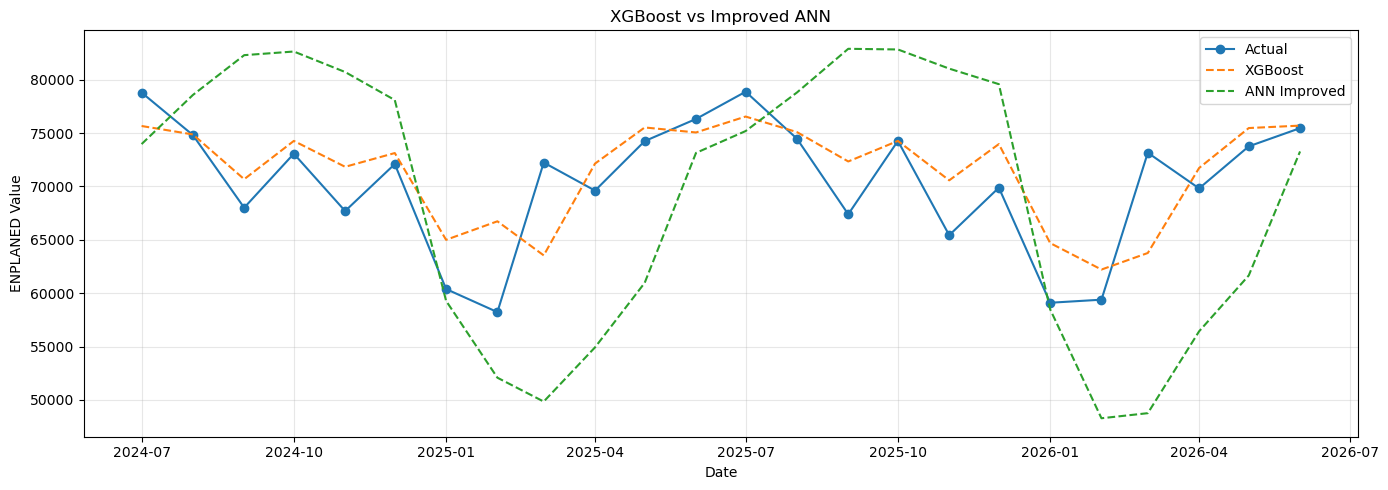

In [14]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# نموذج ANN محسّن
ann_model_v2 = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        learning_rate_init=0.0005,
        max_iter=5000,
        early_stopping=False,
        tol=1e-5,
        random_state=42
    )
)

# تدريب النموذج
ann_model_v2.fit(X_train, y_train)

# التنبؤ
ann_pred_v2 = ann_model_v2.predict(X_test)

# تقييم الأداء
ann_mae_v2 = mean_absolute_error(y_test, ann_pred_v2)
ann_rmse_v2 = np.sqrt(mean_squared_error(y_test, ann_pred_v2))
ann_mape_v2 = np.mean(
    np.abs((y_test.to_numpy() - ann_pred_v2) / y_test.to_numpy())
) * 100

print("نتائج ANN المحسّن:")
print(f"MAE: {ann_mae_v2:.2f}")
print(f"RMSE: {ann_rmse_v2:.2f}")
print(f"MAPE: {ann_mape_v2:.2f}%")
print("عدد التكرارات المستخدمة:", ann_model_v2[-1].n_iter_)

# رسم المقارنة
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test.values, marker="o", label="Actual")
plt.plot(y_test.index, xgb_pred, linestyle="--", label="XGBoost")
plt.plot(y_test.index, ann_pred_v2, linestyle="--", label="ANN Improved")

plt.title("XGBoost vs Improved ANN")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

نتائج ANN مع تطبيع الهدف:
MAE: 3469.09
RMSE: 4213.00
MAPE: 5.17%
عدد التكرارات: 389


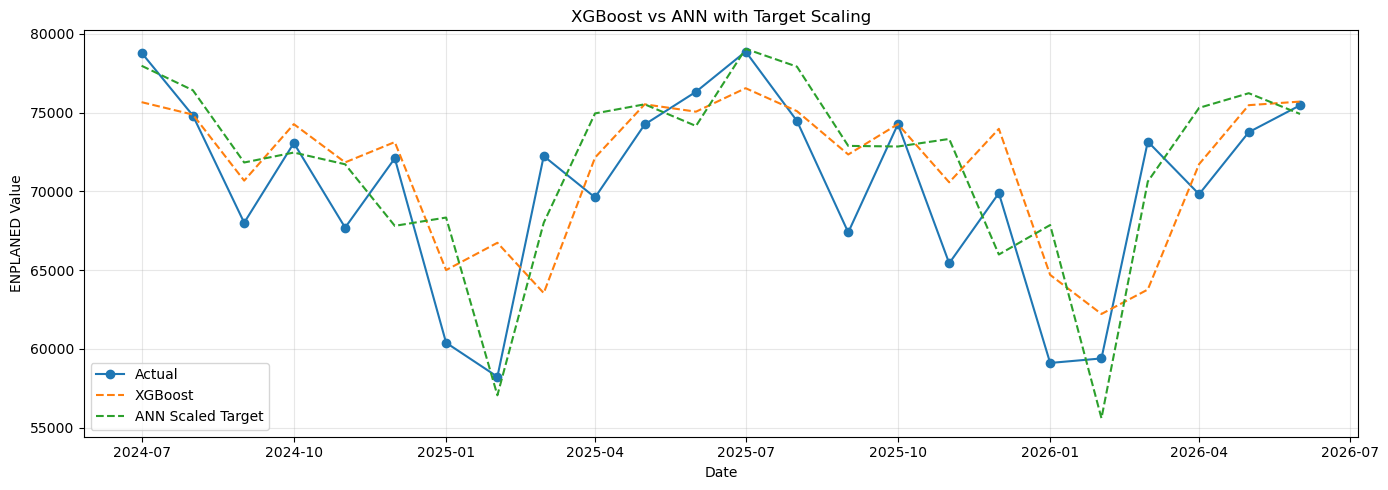

In [15]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# تطبيع خصائص الإدخال وقيم الهدف
ann_model_v3 = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(16, 8),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            max_iter=3000,
            early_stopping=False,
            random_state=42
        )
    ),
    transformer=StandardScaler()
)

# التدريب والتنبؤ
ann_model_v3.fit(X_train, y_train)
ann_pred_v3 = ann_model_v3.predict(X_test)

# تقييم الأداء
ann_mae_v3 = mean_absolute_error(y_test, ann_pred_v3)
ann_rmse_v3 = np.sqrt(mean_squared_error(y_test, ann_pred_v3))
ann_mape_v3 = np.mean(
    np.abs((y_test.to_numpy() - ann_pred_v3) / y_test.to_numpy())
) * 100

print("نتائج ANN مع تطبيع الهدف:")
print(f"MAE: {ann_mae_v3:.2f}")
print(f"RMSE: {ann_rmse_v3:.2f}")
print(f"MAPE: {ann_mape_v3:.2f}%")

print(
    "عدد التكرارات:",
    ann_model_v3.regressor_[-1].n_iter_
)

# رسم المقارنة
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test.values, label="Actual", marker="o")
plt.plot(y_test.index, xgb_pred, label="XGBoost", linestyle="--")
plt.plot(y_test.index, ann_pred_v3, label="ANN Scaled Target", linestyle="--")

plt.title("XGBoost vs ANN with Target Scaling")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

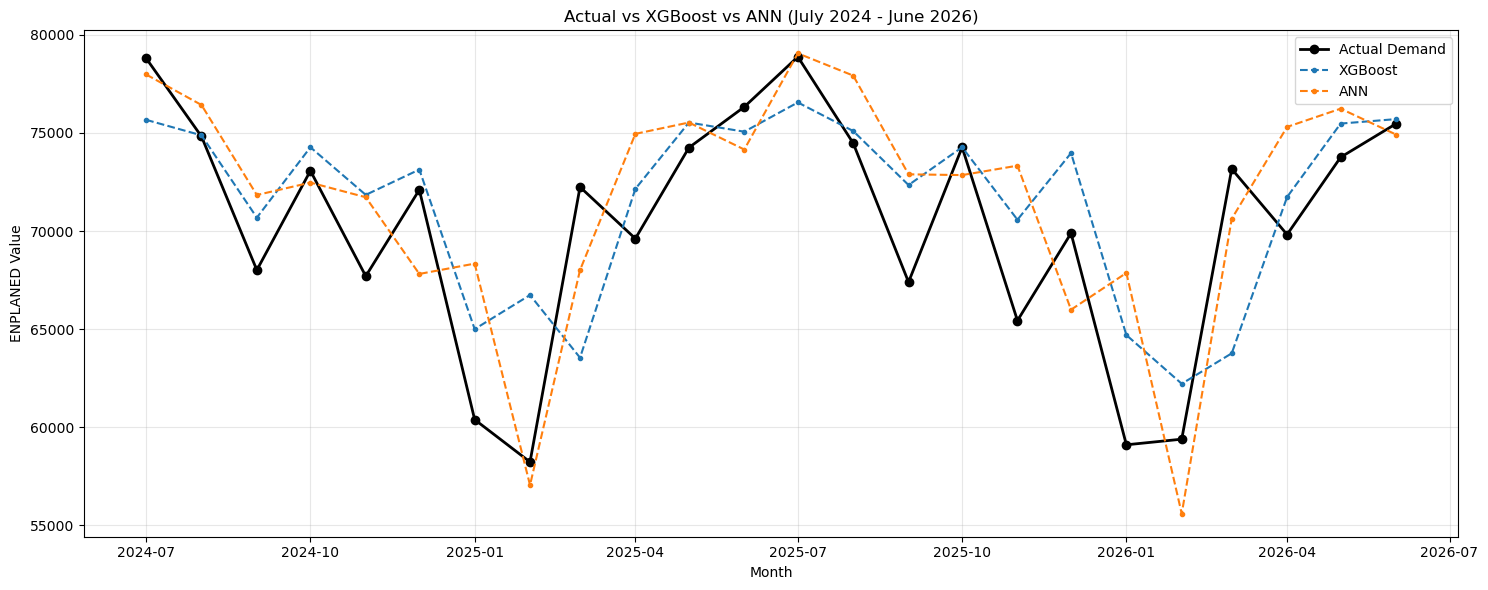

In [16]:
plt.figure(figsize=(15, 6))

plt.plot(
    y_test.index,
    y_test.values,
    color="black",
    linewidth=2,
    marker="o",
    label="Actual Demand"
)

plt.plot(
    y_test.index,
    xgb_pred,
    linestyle="--",
    marker=".",
    label="XGBoost"
)

plt.plot(
    y_test.index,
    ann_pred_v3,
    linestyle="--",
    marker=".",
    label="ANN"
)

plt.title("Actual vs XGBoost vs ANN (July 2024 - June 2026)")
plt.xlabel("Month")
plt.ylabel("ENPLANED Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# إنشاء جدول مقارنة النتائج
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive",
        "XGBoost",
        "ANN"
    ],
    "MAE": [
        1696.04,
        mean_absolute_error(y_test, xgb_pred),
        mean_absolute_error(y_test, ann_pred_v3)
    ],
    "RMSE": [
        2060.15,
        np.sqrt(mean_squared_error(y_test, xgb_pred)),
        np.sqrt(mean_squared_error(y_test, ann_pred_v3))
    ],
    "MAPE (%)": [
        2.40,
        np.mean(np.abs((y_test.to_numpy() - xgb_pred) / y_test.to_numpy())) * 100,
        np.mean(np.abs((y_test.to_numpy() - ann_pred_v3) / y_test.to_numpy())) * 100
    ]
})

comparison = comparison.round(2)

display(comparison)

# حفظ جدول المقارنة
comparison.to_csv("model_comparison.csv", index=False)

print("تم حفظ النتائج في model_comparison.csv")

,Model,MAE,RMSE,MAPE (%)
0,Seasonal Naive,1696.04,2060.15,2.40
1,XGBoost,3247.50,4199.64,4.82
2,ANN,3469.09,4213.00,5.17


تم حفظ النتائج في model_comparison.csv


In [18]:
# إنشاء جدول القيم الفعلية والتنبؤات
forecast_comparison = pd.DataFrame({
    "Date": y_test.index,
    "Actual": y_test.to_numpy(),
    "Seasonal_Naive": baseline_pred,
    "XGBoost": xgb_pred,
    "ANN": ann_pred_v3
})

# حفظ الملف
forecast_comparison.to_csv(
    "test_forecast_comparison.csv",
    index=False
)

print("تم حفظ تنبؤات الاختبار بنجاح.")
print("عدد الأشهر المحفوظة:", len(forecast_comparison))

display(forecast_comparison.head())

تم حفظ تنبؤات الاختبار بنجاح.
عدد الأشهر المحفوظة: 24


,Date,Actual,Seasonal_Naive,XGBoost,ANN
0,2024-07-01,78804,75379,75667.375000,77978.479080
1,2024-08-01,74819,71494,74876.773438,76424.100927
2,2024-09-01,68010,66862,70682.812500,71835.231677
3,2024-10-01,73071,73046,74270.304688,72467.818068
4,2024-11-01,67699,68419,71842.937500,71722.072432


تم إنشاء التنبؤات المستقبلية وحفظها.
عدد الأشهر المتوقعة: 30
الفترة: 2026-07 إلى 2028-12


/var/folders/hw/8swtb_bn5xv82r5f3jw9xz2w0000gp/T/ipykernel_1299/822038926.py:101: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  future_forecast = future_forecast.round(2)


,Date,Seasonal_Naive,XGBoost,ANN
0,2026-07-01,78880,76867.21,76660.19
1,2026-08-01,74477,75124.38,75613.87
2,2026-09-01,67397,67597.88,70965.52
3,2026-10-01,74270,73580.93,72004.39
4,2026-11-01,65435,67265.80,70621.00


,Date,Seasonal_Naive,XGBoost,ANN
25,2028-08-01,74477,75124.38,76521.83
26,2028-09-01,67397,69181.73,75242.89
27,2028-10-01,74270,73538.25,73231.29
28,2028-11-01,65435,67764.18,73014.63
29,2028-12-01,69889,69383.29,72982.02


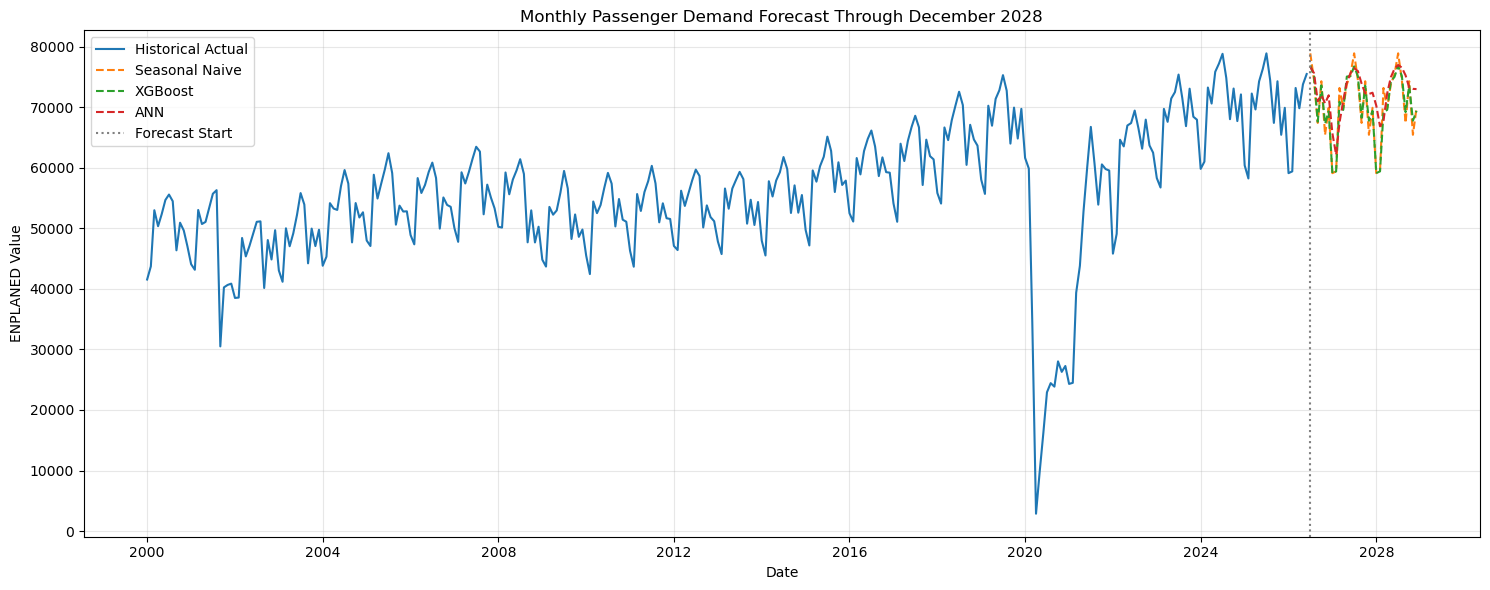

In [19]:
from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. تدريب النموذجين على جميع البيانات المتاحة
xgb_final = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42
)
xgb_final.fit(X, y)

ann_final = TransformedTargetRegressor(
    regressor=make_pipeline(
        StandardScaler(),
        MLPRegressor(
            hidden_layer_sizes=(16, 8),
            activation="relu",
            solver="adam",
            learning_rate_init=0.001,
            max_iter=3000,
            random_state=42
        )
    ),
    transformer=StandardScaler()
)
ann_final.fit(X, y)

# 2. إعداد الأشهر المستقبلية
future_dates = pd.date_range(
    start="2026-07-01",
    end="2028-12-01",
    freq="MS"
)

# استخدام السلسلة الأصلية ثم إضافة التنبؤات تدريجيًا
history_xgb = ts.copy().astype(float)
history_ann = ts.copy().astype(float)

future_xgb = []
future_ann = []

def make_future_features(history, date, time_index):
    return pd.DataFrame([{
        "year": date.year,
        "month": date.month,
        "quarter": date.quarter,
        "time_index": time_index,
        "lag_1": history.iloc[-1],
        "lag_2": history.iloc[-2],
        "lag_3": history.iloc[-3],
        "lag_6": history.iloc[-6],
        "lag_12": history.iloc[-12],
        "rolling_mean_3": history.iloc[-3:].mean(),
        "rolling_mean_12": history.iloc[-12:].mean()
    }], index=[date])[X.columns]

for step, date in enumerate(future_dates):
    time_index = len(ts) + step

    # XGBoost
    features_xgb = make_future_features(
        history_xgb, date, time_index
    )
    pred_xgb = float(xgb_final.predict(features_xgb)[0])
    pred_xgb = max(0, pred_xgb)
    future_xgb.append(pred_xgb)
    history_xgb.loc[date] = pred_xgb

    # ANN
    features_ann = make_future_features(
        history_ann, date, time_index
    )
    pred_ann = float(ann_final.predict(features_ann)[0])
    pred_ann = max(0, pred_ann)
    future_ann.append(pred_ann)
    history_ann.loc[date] = pred_ann

# 3. Seasonal Naive: تكرار نمط آخر 12 شهرًا
last_year = ts.iloc[-12:].to_numpy()
future_naive = np.tile(last_year, 3)[:len(future_dates)]

# 4. حفظ التنبؤات في جدول
future_forecast = pd.DataFrame({
    "Date": future_dates,
    "Seasonal_Naive": future_naive,
    "XGBoost": future_xgb,
    "ANN": future_ann
})

future_forecast = future_forecast.round(2)
future_forecast.to_csv("passenger_demand_forecast_2026_2028.csv",
                       index=False)

print("تم إنشاء التنبؤات المستقبلية وحفظها.")
print("عدد الأشهر المتوقعة:", len(future_forecast))
print("الفترة:", future_dates.min().strftime("%Y-%m"),
      "إلى", future_dates.max().strftime("%Y-%m"))
display(future_forecast.head())
display(future_forecast.tail())

# 5. رسم الطلب الفعلي والتنبؤات
plt.figure(figsize=(15, 6))
plt.plot(ts.index, ts.values, label="Historical Actual", linewidth=1.5)
plt.plot(future_dates, future_naive, "--", label="Seasonal Naive")
plt.plot(future_dates, future_xgb, "--", label="XGBoost")
plt.plot(future_dates, future_ann, "--", label="ANN")

plt.axvline(pd.Timestamp("2026-07-01"),
            color="gray", linestyle=":", label="Forecast Start")
plt.title("Monthly Passenger Demand Forecast Through December 2028")
plt.xlabel("Date")
plt.ylabel("ENPLANED Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# استخراج السنة والشهر من التاريخ
future_forecast["Year"] = future_forecast["Date"].dt.year
future_forecast["Month"] = future_forecast["Date"].dt.month

month_names = {
    1: "January", 2: "February", 3: "March",
    4: "April", 5: "May", 6: "June",
    7: "July", 8: "August", 9: "September",
    10: "October", 11: "November", 12: "December"
}

models = ["Seasonal_Naive", "XGBoost", "ANN"]

# أعلى شهر متوقع في كل سنة لكل نموذج
for model in models:
    print(f"\nأعلى شهر متوقع في كل سنة - {model}")

    yearly_peak = (
        future_forecast.loc[
            future_forecast.groupby("Year")[model].idxmax(),
            ["Year", "Date", model]
        ].copy()
    )

    yearly_peak["Month_Name"] = yearly_peak["Date"].dt.month.map(month_names)

    display(
        yearly_peak[["Year", "Month_Name", model]]
        .rename(columns={model: "Predicted_Demand"})
        .reset_index(drop=True)
    )

# أعلى خمسة أشهر خلال كامل الفترة لكل نموذج
for model in models:
    print(f"\nأعلى خمسة أشهر متوقعة - {model}")

    top_months = future_forecast.nlargest(5, model)[
        ["Date", model]
    ].copy()

    top_months["Month_Name"] = top_months["Date"].dt.strftime("%Y-%m")

    display(
        top_months[["Month_Name", model]]
        .rename(columns={model: "Predicted_Demand"})
        .reset_index(drop=True)
    )

# حفظ الجدول بعد إضافة معلومات السنة والشهر
future_forecast.to_csv(
    "passenger_demand_forecast_2026_2028.csv",
    index=False
)

print("تم تحديث ملف التنبؤات بنجاح.")


أعلى شهر متوقع في كل سنة - Seasonal_Naive


,Year,Month_Name,Predicted_Demand
0,2026,July,78880
1,2027,July,78880
2,2028,July,78880



أعلى شهر متوقع في كل سنة - XGBoost


,Year,Month_Name,Predicted_Demand
0,2026,July,76867.21
1,2027,July,76735.05
2,2028,July,76824.79



أعلى شهر متوقع في كل سنة - ANN


...


أعلى خمسة أشهر متوقعة - XGBoost


,Month_Name,Predicted_Demand
0,2026-07,76867.21
1,2028-07,76824.79
2,2027-07,76735.05
3,2027-06,75135.46
4,2026-08,75124.38



أعلى خمسة أشهر متوقعة - ANN


,Month_Name,Predicted_Demand
0,2028-07,76959.90
1,2026-07,76660.19
2,2028-08,76521.83
3,2027-07,76435.78
4,2028-06,76344.17


تم تحديث ملف التنبؤات بنجاح.


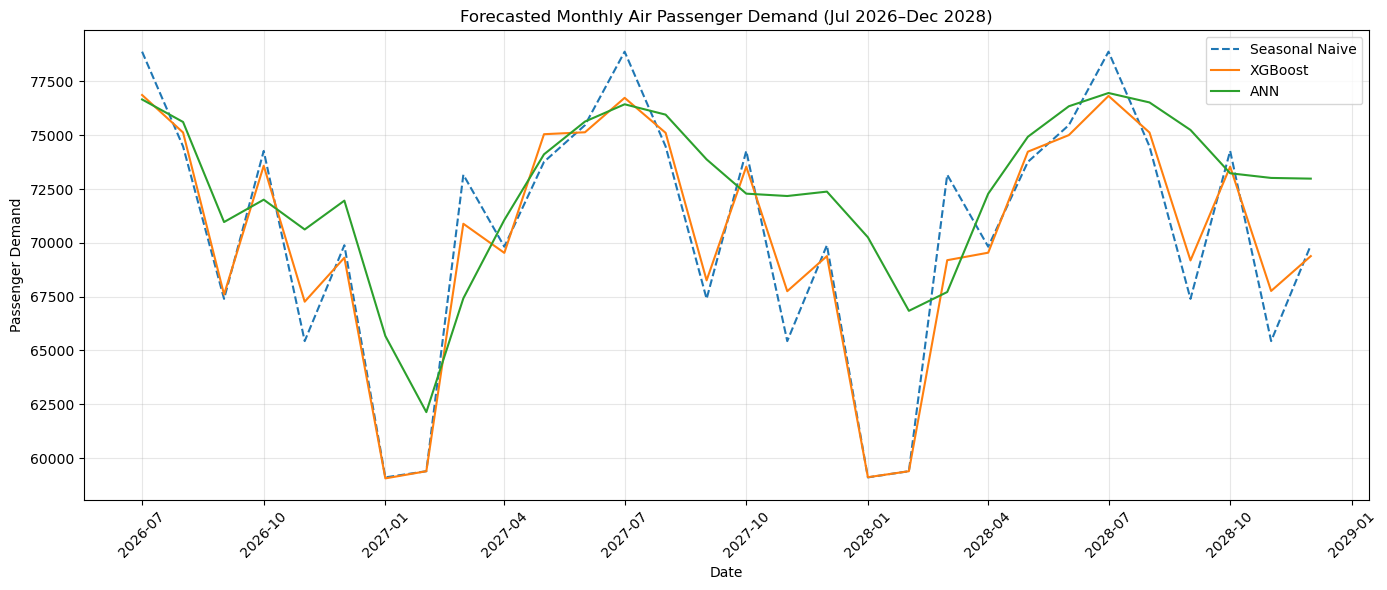

In [21]:
plt.figure(figsize=(14, 6))

plt.plot(
    future_forecast["Date"],
    future_forecast["Seasonal_Naive"],
    label="Seasonal Naive",
    linestyle="--"
)

plt.plot(
    future_forecast["Date"],
    future_forecast["XGBoost"],
    label="XGBoost"
)

plt.plot(
    future_forecast["Date"],
    future_forecast["ANN"],
    label="ANN"
)

plt.title("Forecasted Monthly Air Passenger Demand (Jul 2026–Dec 2028)")
plt.xlabel("Date")
plt.ylabel("Passenger Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

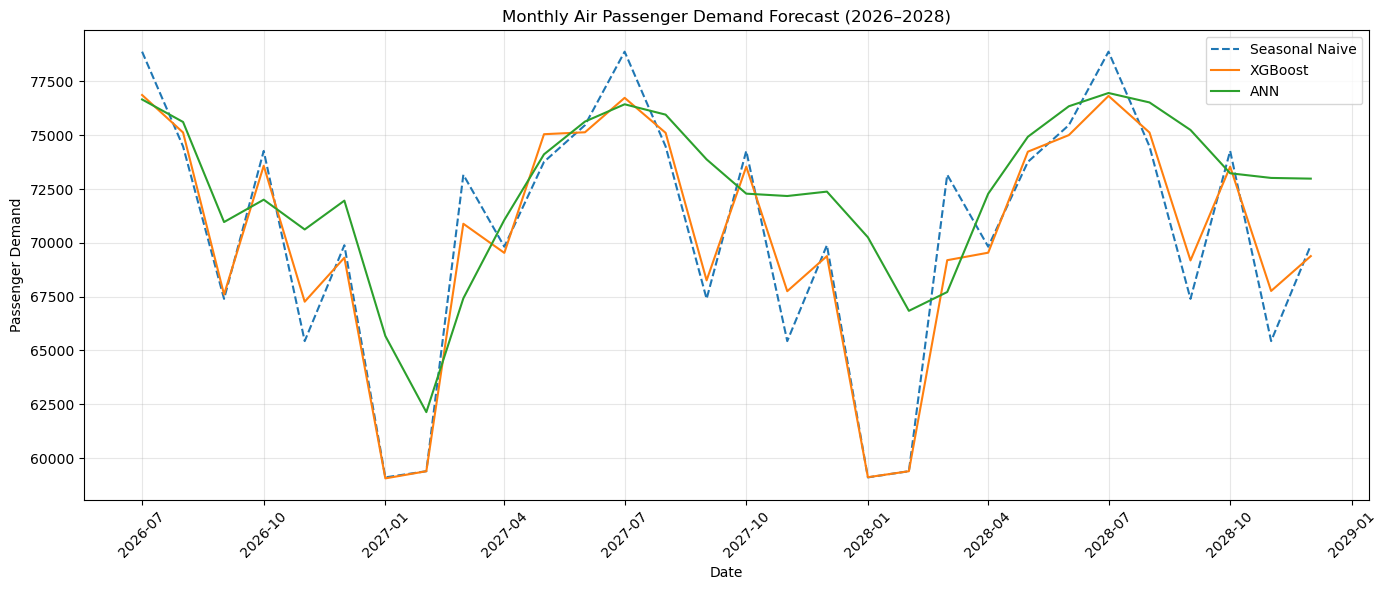

تم حفظ الرسم البياني بنجاح.


In [22]:
plt.figure(figsize=(14, 6))

plt.plot(future_forecast["Date"], future_forecast["Seasonal_Naive"],
         label="Seasonal Naive", linestyle="--")
plt.plot(future_forecast["Date"], future_forecast["XGBoost"],
         label="XGBoost")
plt.plot(future_forecast["Date"], future_forecast["ANN"],
         label="ANN")

plt.title("Monthly Air Passenger Demand Forecast (2026–2028)")
plt.xlabel("Date")
plt.ylabel("Passenger Demand")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("forecast_comparison_2026_2028.png", dpi=300, bbox_inches="tight")
plt.show()

print("تم حفظ الرسم البياني بنجاح.")

In [23]:
import joblib

# حفظ نموذج XGBoost
joblib.dump(xgb_final, "xgboost_final_model.pkl")

# حفظ نموذج ANN
joblib.dump(ann_final, "ann_final_model.pkl")

# حفظ أسماء الخصائص وترتيبها
joblib.dump(list(X.columns), "model_features.pkl")

print("تم حفظ النماذج والخصائص بنجاح!")

تم حفظ النماذج والخصائص بنجاح!


In [24]:
%pip install streamlit

Note: you may need to restart the kernel to use updated packages.


In [25]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

# 1. القيم الفعلية وتنبؤات النماذج
actual = np.asarray(y_test, dtype=float).reshape(-1)

predictions = {
    "Seasonal Naive": np.asarray(baseline_pred, dtype=float).reshape(-1),
    "XGBoost": np.asarray(xgb_pred, dtype=float).reshape(-1),
    "ANN": np.asarray(ann_pred_v3, dtype=float).reshape(-1)
}

# 2. التأكد من أن جميع التنبؤات لها نفس عدد الأشهر
for model_name, pred in predictions.items():
    if len(pred) != len(actual):
        raise ValueError(
            f"عدد تنبؤات {model_name} لا يطابق عدد القيم الفعلية."
        )

# 3. حساب مقاييس الأداء
results = []

for model_name, pred in predictions.items():
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mape = np.mean(np.abs((actual - pred) / actual)) * 100

    results.append({
        "Model": model_name,
        "MAE": round(mae, 2),
        "RMSE": round(rmse, 2),
        "MAPE (%)": round(mape, 2)
    })

comparison_final = pd.DataFrame(results)

# 4. عرض جدول المقارنة
print("=" * 55)
print("FINAL MODEL COMPARISON")
print("=" * 55)
print(f"Test months: {len(actual)}")
print("Test period: July 2024 - June 2026")
print("Lower error values indicate better performance.\n")

display(comparison_final)

# 5. تحديد الأفضل بين XGBoost وANN
ml_models = comparison_final[
    comparison_final["Model"].isin(["XGBoost", "ANN"])
].sort_values("MAPE (%)")

best_ml = ml_models.iloc[0]

print("\n" + "=" * 55)
print("FINAL CONCLUSION")
print("=" * 55)

print(
    f"Among XGBoost and ANN, {best_ml['Model']} performed better "
    "on the test set according to MAPE."
)

# 6. توضيح نتيجة خط الأساس
best_overall = comparison_final.sort_values("MAPE (%)").iloc[0]

print(
    f"The lowest MAPE among all three methods was achieved by "
    f"{best_overall['Model']} ({best_overall['MAPE (%)']:.2f}%)."
)

# 7. حفظ جدول النتائج النهائي
comparison_final.to_csv("final_model_comparison.csv", index=False)
print("\nResults saved to final_model_comparison.csv")

FINAL MODEL COMPARISON
Test months: 24
Test period: July 2024 - June 2026
Lower error values indicate better performance.



,Model,MAE,RMSE,MAPE (%)
0,Seasonal Naive,1696.04,2060.15,2.40
1,XGBoost,3247.50,4199.64,4.82
2,ANN,3469.09,4213.00,5.17



FINAL CONCLUSION
Among XGBoost and ANN, XGBoost performed better on the test set according to MAPE.
The lowest MAPE among all three methods was achieved by Seasonal Naive (2.40%).

Results saved to final_model_comparison.csv
